# Stage 7: Evaluation — Zero-Shot vs. Fine-Tuned

**Project:** Aspect-Level Customer Review Intelligence via Fine-Tuned Small Language Models

Scores the fine-tuned model's generations (captured by
`03_finetune_colab.ipynb` on Colab, brought back into `outputs/raw_generations/finetuned/`)
using the *exact same* `src/eval_metrics.py` that scored the zero-shot
baseline in `02_baseline.ipynb` — per `../docs/Customer_Review_Intelligence_Review0.md`
§14 and the §10.3 fairness requirement (identical scoring code, not just
identical prompts).

**No model is called here.** Only already-captured files are read and scored.

**Two evaluations happen:**
1. The 300-sentence held-out test set — full M1–M5, strict and lenient —
   this produces the actual zero-shot-vs-fine-tuned comparison.
2. The 800-sentence `phaseb_extraction_check.jsonl` bonus set (Decision
   D17) — extraction-only (M2-equivalent), since this gold data has no
   polarity by design.


## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

import eval_metrics as em

DATA_DIR = ROOT / "data" / "processed"
GEN_DIR = ROOT / "outputs" / "raw_generations" / "finetuned"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]

for p in [DATA_DIR / "test.jsonl", DATA_DIR / "phaseb_extraction_check.jsonl",
          GEN_DIR / "test_generations.jsonl", GEN_DIR / "phaseb_generations.jsonl"]:
    print(f"{'OK ' if p.exists() else 'MISSING':8s} {p}")


OK       /home/sreekanth/Downloads/SEM 7/asmta/data/processed/test.jsonl
OK       /home/sreekanth/Downloads/SEM 7/asmta/data/processed/phaseb_extraction_check.jsonl
OK       /home/sreekanth/Downloads/SEM 7/asmta/outputs/raw_generations/finetuned/test_generations.jsonl
OK       /home/sreekanth/Downloads/SEM 7/asmta/outputs/raw_generations/finetuned/phaseb_generations.jsonl


## 2. Load gold + fine-tuned generations, join by sentence_id

Joined explicitly by `sentence_id` rather than assumed to be in the same
order — cheap to get right, expensive to get wrong silently.


In [2]:
test_gold = load_jsonl(DATA_DIR / "test.jsonl")
test_gen = load_jsonl(GEN_DIR / "test_generations.jsonl")

gen_by_id = {r["sentence_id"]: r for r in test_gen}
missing = [g["sentence_id"] for g in test_gold if g["sentence_id"] not in gen_by_id]
assert not missing, f"{len(missing)} test sentences have no fine-tuned generation: {missing[:5]}"

test_score_input = [
    {
        "sentence_id": g["sentence_id"],
        "gold_aspects": g["target"]["aspects"],
        "raw_output": gen_by_id[g["sentence_id"]]["raw_output"],
    }
    for g in test_gold
]
print(f"Joined {len(test_score_input)} test records (gold x fine-tuned generation).")


Joined 300 test records (gold x fine-tuned generation).


In [3]:
phaseb_gold = load_jsonl(DATA_DIR / "phaseb_extraction_check.jsonl")
phaseb_gen = load_jsonl(GEN_DIR / "phaseb_generations.jsonl")

phaseb_gen_by_id = {r["sentence_id"]: r for r in phaseb_gen}
missing_pb = [g["sentence_id"] for g in phaseb_gold if g["sentence_id"] not in phaseb_gen_by_id]
assert not missing_pb, f"{len(missing_pb)} phaseb sentences have no fine-tuned generation"

phaseb_score_input = [
    {
        "sentence_id": g["sentence_id"],
        "gold_aspects": g["gold_aspects"],  # plain strings, no polarity — D17
        "raw_output": phaseb_gen_by_id[g["sentence_id"]]["raw_output"],
    }
    for g in phaseb_gold
]
print(f"Joined {len(phaseb_score_input)} phaseb records (gold x fine-tuned generation).")


Joined 800 phaseb records (gold x fine-tuned generation).


## 3. Score — fine-tuned, on the same 300-sentence test set as zero-shot

In [4]:
ft_strict = em.evaluate_strict(test_score_input)
ft_lenient = em.evaluate_lenient(test_score_input)

print("FINE-TUNED — STRICT:")
for k, v in ft_strict.items():
    print(f"  {k}: {v:.3f}" if isinstance(v, float) else f"  {k}: {v}")

print("\nFINE-TUNED — LENIENT:")
for k, v in ft_lenient.items():
    print(f"  {k}: {v:.3f}" if isinstance(v, float) else f"  {k}: {v}")


FINE-TUNED — STRICT:
  n_records: 300
  M1_json_validity_rate: 1.000
  M2_aspect_precision: 0.657
  M2_aspect_recall: 0.341
  M2_aspect_f1: 0.449
  M3_polarity_accuracy: 0.789
  M4_joint_precision: 0.519
  M4_joint_recall: 0.269
  M4_joint_f1: 0.354
  M5_empty_case_accuracy: 1.000

FINE-TUNED — LENIENT:
  n_records: 300
  M1_json_validity_rate: 1.000
  M2_aspect_precision: 0.657
  M2_aspect_recall: 0.341
  M2_aspect_f1: 0.449
  M3_polarity_accuracy: 0.789
  M4_joint_precision: 0.519
  M4_joint_recall: 0.269
  M4_joint_f1: 0.354
  M5_empty_case_accuracy: 1.000


## 4. The actual comparison: Zero-Shot vs. Fine-Tuned (§15.1)

In [5]:
existing = pd.read_csv(RESULTS_DIR / "results_table.csv")
zero_shot_rows = existing[existing["condition"] == "zero_shot"]

new_rows = pd.DataFrame([
    {"condition": "fine_tuned", "parser": "strict", **ft_strict},
    {"condition": "fine_tuned", "parser": "lenient", **ft_lenient},
])
# rename to match the existing table's column names
new_rows = new_rows.rename(columns={
    "M2_aspect_f1": "M2_aspect_f1", "M3_polarity_accuracy": "M3_polarity_accuracy",
})[["condition", "parser", "n_records", "M1_json_validity_rate", "M2_aspect_f1",
    "M3_polarity_accuracy", "M4_joint_f1", "M5_empty_case_accuracy"]]

comparison = pd.concat([zero_shot_rows, new_rows], ignore_index=True)
comparison


,condition,parser,n_records,M1_json_validity_rate,M2_aspect_f1,M3_polarity_accuracy,M4_joint_f1,M5_empty_case_accuracy
0,zero_shot,strict,300,0.126667,0.132867,0.842105,0.111888,0.913580
1,zero_shot,lenient,300,0.883333,0.304487,0.778947,0.237179,0.148148
2,fine_tuned,strict,300,1.000000,0.449367,0.788732,0.354430,1.000000
3,fine_tuned,lenient,300,1.000000,0.449367,0.788732,0.354430,1.000000


In [6]:
# Pivoted view — the headline table for the write-up (§15.1 style).
pivot = comparison.set_index(["parser", "condition"])[
    ["M1_json_validity_rate", "M2_aspect_f1", "M3_polarity_accuracy",
     "M4_joint_f1", "M5_empty_case_accuracy"]
].unstack("condition")
pivot


M1_json_validity_rate           M2_aspect_f1            \
condition            fine_tuned zero_shot   fine_tuned zero_shot   
parser                                                             
lenient                     1.0  0.883333     0.449367  0.304487   
strict                      1.0  0.126667     0.449367  0.132867   

          M3_polarity_accuracy           M4_joint_f1            \
condition           fine_tuned zero_shot  fine_tuned zero_shot   
parser                                                           
lenient               0.788732  0.778947     0.35443  0.237179   
strict                0.788732  0.842105     0.35443  0.111888   

          M5_empty_case_accuracy            
condition             fine_tuned zero_shot  
parser                                      
lenient                      1.0  0.148148  
strict                       1.0  0.913580

**Read this against the doc's own framing (§15.4): lead with M1 and M5, be
honest about M3.** If fine-tuning did what H2 predicts, the largest jumps
should be in M1 (format compliance) and M5 (restraint), with M3 (polarity
accuracy) improving the least — because the base model already understood
sentiment reasonably well zero-shot (see notebook 02's finding: lenient M3
was already 77.9%). A small or even negative M3 delta is not a weak result
here; it's the predicted one.


## 4.5 The fine-tuning effect, as a chart

This data has existed since this notebook first ran — it was only ever
printed as a table, never plotted. Grouped bars, lenient parsing (the fairer
read per §15.4), zero-shot vs. fine-tuned across all five metrics, on the
same 300-sentence held-out test set.


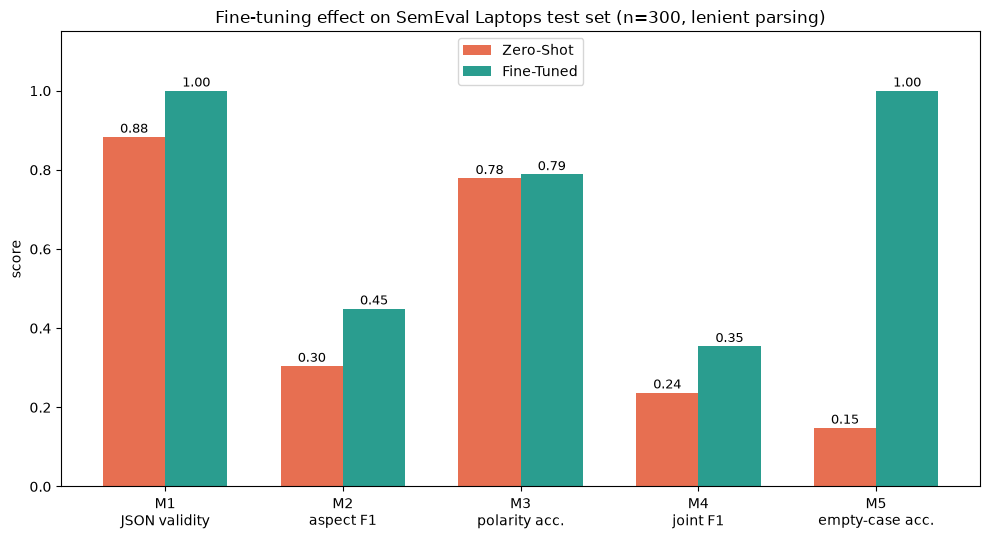

In [7]:
metrics = ["M1_json_validity_rate", "M2_aspect_f1", "M3_polarity_accuracy",
           "M4_joint_f1", "M5_empty_case_accuracy"]
metric_labels = ["M1\nJSON validity", "M2\naspect F1", "M3\npolarity acc.",
                  "M4\njoint F1", "M5\nempty-case acc."]

lenient_rows = comparison[comparison["parser"] == "lenient"].set_index("condition")
zero_shot_vals = [lenient_rows.loc["zero_shot", m] for m in metrics]
fine_tuned_vals = [lenient_rows.loc["fine_tuned", m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))
bars_zs = ax.bar(x - width / 2, zero_shot_vals, width, label="Zero-Shot", color="#e76f51")
bars_ft = ax.bar(x + width / 2, fine_tuned_vals, width, label="Fine-Tuned", color="#2a9d8f")

for bars in (bars_zs, bars_ft):
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("score")
ax.set_title("Fine-tuning effect on SemEval Laptops test set (n=300, lenient parsing)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "benchmark_zero_shot_vs_finetuned.png", dpi=150)
plt.show()


## 5. Score — phaseB extraction-only bonus check (800 sentences, D17)

In [8]:
pb_strict = em.score_extraction_only(phaseb_score_input, em.parse_strict)
pb_lenient = em.score_extraction_only(phaseb_score_input, em.parse_lenient)

print("PHASEB EXTRACTION-ONLY — STRICT:", pb_strict)
print("PHASEB EXTRACTION-ONLY — LENIENT:", pb_lenient)


PHASEB EXTRACTION-ONLY — STRICT: {'n_records': 800, 'M1_json_validity_rate': 1.0, 'aspect_precision': 0.7195121951219512, 'aspect_recall': 0.3630769230769231, 'aspect_f1': 0.48261758691206547}
PHASEB EXTRACTION-ONLY — LENIENT: {'n_records': 800, 'M1_json_validity_rate': 1.0, 'aspect_precision': 0.7195121951219512, 'aspect_recall': 0.3630769230769231, 'aspect_f1': 0.48261758691206547}


M3/M4/M5 are not defined here — this gold data has no polarity by
design (Decision D17). This is a genuinely independent 800-sentence check
(zero text overlap with the training pool, confirmed in notebook 00), so
its M2-equivalent aspect F1 is the best available signal on *unseen*
generalisation, separate from the 300-sentence test set the model's
checkpoint selection was implicitly exposed to via validation-loss
monitoring.


In [9]:
pb_rows = pd.DataFrame([
    {"condition": "fine_tuned_phaseb_extraction_only", "parser": "strict",
     "n_records": pb_strict["n_records"], "M1_json_validity_rate": pb_strict["M1_json_validity_rate"],
     "M2_aspect_f1": pb_strict["aspect_f1"], "M3_polarity_accuracy": None,
     "M4_joint_f1": None, "M5_empty_case_accuracy": None},
    {"condition": "fine_tuned_phaseb_extraction_only", "parser": "lenient",
     "n_records": pb_lenient["n_records"], "M1_json_validity_rate": pb_lenient["M1_json_validity_rate"],
     "M2_aspect_f1": pb_lenient["aspect_f1"], "M3_polarity_accuracy": None,
     "M4_joint_f1": None, "M5_empty_case_accuracy": None},
])

final_table = pd.concat([comparison, pb_rows], ignore_index=True)
final_table.to_csv(RESULTS_DIR / "results_table.csv", index=False)
print(f"Wrote {RESULTS_DIR / 'results_table.csv'} ({len(final_table)} rows)")
final_table


Wrote /home/sreekanth/Downloads/SEM 7/asmta/results/results_table.csv (6 rows)


,condition,parser,n_records,M1_json_validity_rate,M2_aspect_f1,M3_polarity_accuracy,M4_joint_f1,M5_empty_case_accuracy
0,zero_shot,strict,300,0.126667,0.132867,0.842105,0.111888,0.91358
1,zero_shot,lenient,300,0.883333,0.304487,0.778947,0.237179,0.148148
2,fine_tuned,strict,300,1.000000,0.449367,0.788732,0.35443,1.0
3,fine_tuned,lenient,300,1.000000,0.449367,0.788732,0.35443,1.0
4,fine_tuned_phaseb_extraction_only,strict,800,1.000000,0.482618,None,None,None
5,fine_tuned_phaseb_extraction_only,lenient,800,1.000000,0.482618,None,None,None


## 6. Error analysis — first-pass heuristic categorization (§14.4)

**This is a starting point for the manual read the doc asks for, not a
replacement for it.** §14.4 is explicit: *"Manually inspect ~50 fine-tuned
outputs... Actually read them."* What follows programmatically detects
likely category per sentence (boundary error, missed aspect, spurious
aspect, polarity flip, neutral confusion, schema violation) on a fixed-seed
sample of 50, using lenient parsing so presentation issues don't masquerade
as comprehension errors here. Saved to `results/error_analysis.csv` for
actual manual review — treat the `detected_issues` column as a first guess
to check, not a verdict.


In [10]:
def categorize(gold_aspects, raw_output):
    parsed = em.parse_lenient(raw_output)
    if parsed is None:
        return ["schema_violation"]

    pred_list = parsed.get("aspects", [])
    gold_norm = [(em._normalize(a["aspect"]), a["sentiment"], a["aspect"]) for a in gold_aspects]
    pred_norm = [(em._normalize(p["aspect"]), p.get("sentiment"), p["aspect"]) for p in pred_list]

    gold_matched, pred_matched = set(), set()
    issues = []

    # exact span matches first
    for gi, (gn, gp, go) in enumerate(gold_norm):
        for pi, (pn, pp, po) in enumerate(pred_norm):
            if pi in pred_matched:
                continue
            if gn == pn:
                gold_matched.add(gi)
                pred_matched.add(pi)
                if gp != pp:
                    if gp == "neutral" or pp == "neutral":
                        issues.append(f"neutral_confusion({go}: {gp}->{pp})")
                    else:
                        issues.append(f"polarity_flip({go}: {gp}->{pp})")
                break

    # boundary errors: unmatched gold with substring overlap against unmatched pred
    for gi, (gn, gp, go) in enumerate(gold_norm):
        if gi in gold_matched:
            continue
        matched_boundary = False
        for pi, (pn, pp, po) in enumerate(pred_norm):
            if pi in pred_matched:
                continue
            if gn in pn or pn in gn:
                issues.append(f"boundary_error(gold={go!r}, pred={po!r})")
                gold_matched.add(gi)
                pred_matched.add(pi)
                matched_boundary = True
                break
        if not matched_boundary:
            issues.append(f"missed_aspect({go})")

    for pi, (pn, pp, po) in enumerate(pred_norm):
        if pi not in pred_matched:
            issues.append(f"spurious_aspect({po})")

    return issues if issues else ["correct"]


In [11]:
SAMPLE_SEED = 42
rng = np.random.default_rng(SAMPLE_SEED)
sample_idx = rng.choice(len(test_gold), size=50, replace=False)

error_rows = []
for i in sample_idx:
    g = test_gold[i]
    raw = gen_by_id[g["sentence_id"]]["raw_output"]
    issues = categorize(g["target"]["aspects"], raw)
    error_rows.append({
        "sentence_id": g["sentence_id"],
        "text": g["text"],
        "gold": json.dumps(g["target"]["aspects"]),
        "raw_output": raw,
        "detected_issues": "; ".join(issues),
    })

error_df = pd.DataFrame(error_rows)
error_df.to_csv(RESULTS_DIR / "error_analysis.csv", index=False)
print(f"Wrote {RESULTS_DIR / 'error_analysis.csv'} ({len(error_df)} sampled sentences)")

from collections import Counter
issue_types = Counter()
for issues in error_df["detected_issues"]:
    for issue in issues.split("; "):
        issue_types[issue.split("(")[0]] += 1
print("\nDetected issue-type frequency across the 50-sample (a sentence can have multiple):")
for issue_type, count in issue_types.most_common():
    print(f"  {issue_type}: {count}")


Wrote /home/sreekanth/Downloads/SEM 7/asmta/results/error_analysis.csv (50 sampled sentences)

Detected issue-type frequency across the 50-sample (a sentence can have multiple):
  correct: 28
  missed_aspect: 23
  neutral_confusion: 8
  spurious_aspect: 5
  boundary_error: 2


### Summary

- `results/results_table.csv` now holds the real zero-shot-vs-fine-tuned
  comparison (M1–M5, strict + lenient) plus the phaseB extraction-only bonus
  rows.
- `figures/benchmark_zero_shot_vs_finetuned.png` — the chart of that
  comparison (§4.5 above).
- `results/error_analysis.csv` holds a 50-sample, fixed-seed, programmatically
  pre-categorized starting point for the manual read §14.4 actually asks
  for — read it before writing anything about error patterns in a report.
- **Next step:** Stage 8, `notebooks/06_application.ipynb` — batch inference
  over the earphone corpus and the four product-intelligence charts (§16.2).
